In [1]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm

from cmfa.functions import ordered_ilr_func


In [2]:
RESULTS_DIR = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [3]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy", allow_pickle=True).item()
true_id = np.load(RESULTS_DIR / "true_composition.npy", allow_pickle=True).item()
print(f"True flux: {true_flux}")
print(f"True isotopologue distribution: {true_id}")

True flux: {'v8': Array(0.215, dtype=float64), 'v1': Array(1., dtype=float64), 'v19': Array(0.05, dtype=float64), 'v20': Array(0.03, dtype=float64), 'v16': Array(0.07, dtype=float64), 'v17': Array(0.23, dtype=float64), 'v18': Array(0.12, dtype=float64), 'v2': Array(0.201, dtype=float64), 'v9': Array(0.296, dtype=float64), 'v3': Array(0.621, dtype=float64), 'v4': Array(0.621, dtype=float64), 'v5': Array(0.621, dtype=float64), 'v6': Array(0.592, dtype=float64), 'v11': Array(1.213, dtype=float64), 'v12': Array(0.296, dtype=float64), 'v13': Array(1.509, dtype=float64), 'v14': Array(1.735, dtype=float64), 'v15': Array(5.561, dtype=float64), 'v10': Array(0.475, dtype=float64), 'v7': Array(0.807, dtype=float64)}
True isotopologue distribution: {'lysx_123456': Array([0.01567147, 0.11709665, 0.24642148, 0.28673379, 0.21348085,
       0.10003428, 0.02056148], dtype=float64), 'valx_12345': Array([0.0128301 , 0.10251097, 0.27570439, 0.34531928, 0.21147698,
       0.05215829], dtype=float64), 'aspx

# Reference 

In [4]:
with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)

with open(RESULTS_DIR / "estimated_fluxes_full.pkl", "rb") as f:
    estimated_fluxes_full = pickle.load(f)

In [5]:
exclude = {"v1", "v16", "v17", "v18", "v19", "v20"}
flux_keys = [k for k in sorted(true_flux.keys(), key=lambda k: int(k[1:])) if k not in exclude]

rows = []
for model in ("trad", "ilr"):
    arr = np.array(estimated_fluxes_full[model])  # shape (N, n_flux)
    for i, flux_name in enumerate(flux_keys):
        col = arr[:, list(true_flux.keys()).index(flux_name)]
        rows.append({
            "model": model,
            "flux": flux_name,
            "true_value": float(true_flux[flux_name]),
            "median": float(np.median(col)),
            "min": float(np.min(col)),
            "max": float(np.max(col)),
            "q25": float(np.quantile(col, 0.25)),
            "q75": float(np.quantile(col, 0.75)),
        })

summary_df = pl.DataFrame(rows)
summary_df.write_csv(RESULTS_DIR / "estimated_fluxes_full_summary.csv")
print(summary_df.to_pandas().to_string(index=False))

model flux  true_value   median          min      max      q25      q75
 trad   v2       0.201 0.201469 1.578093e-01 0.241478 0.193226 0.209488
 trad   v3       0.621 0.621469 5.778093e-01 0.661478 0.613226 0.629488
 trad   v4       0.621 0.621469 5.778093e-01 0.661478 0.613226 0.629488
 trad   v5       0.621 0.621469 5.778093e-01 0.661478 0.613226 0.629488
 trad   v6       0.592 0.592938 5.056186e-01 0.672957 0.576452 0.608975
 trad   v7       0.807 0.809973 5.195217e-01 2.561482 0.718245 0.930912
 trad   v8       0.215 0.216067 9.136650e-17 1.981758 0.131384 0.331630
 trad   v9       0.296 0.295791 7.508211e-02 0.753144 0.248062 0.349148
 trad  v10       0.475 0.474298 2.822967e-01 0.923618 0.429835 0.524775
 trad  v11       1.213 1.214406 1.083428e+00 1.334435 1.189678 1.238463
 trad  v12       0.296 0.296469 2.528093e-01 0.336478 0.288226 0.304488
 trad  v13       1.509 1.510875 1.336237e+00 1.670913 1.477904 1.542950
 trad  v14       1.735 1.737344 1.519046e+00 1.937391 1.696130 1

In [6]:
col_rename = {
    "flux": "Flux",
    "true_value": "True value",
    "median": "Median",
    "min": "Min",
    "max": "Max",
    "q25": "Q25",
    "q75": "Q75",
}

for model, label in (("trad", "Traditional I-MFA"), ("ilr", "Compositional I-MFA")):
    df = (
        summary_df.filter(pl.col("model") == model)
        .drop("model")
        .rename(col_rename)
        .to_pandas()
    )
    latex = df.to_latex(
        index=False,
        float_format="%.3f",
        caption=f"Estimated fluxes — {label}",
        label=f"tab:fluxes_{model}",
    )
    print(f"% --- {label} ---")
    print(latex)

% --- Traditional I-MFA ---
\begin{table}
\caption{Estimated fluxes — Traditional I-MFA}
\label{tab:fluxes_trad}
\begin{tabular}{lrrrrrr}
\toprule
Flux & True value & Median & Min & Max & Q25 & Q75 \\
\midrule
v2 & 0.201 & 0.201 & 0.158 & 0.241 & 0.193 & 0.209 \\
v3 & 0.621 & 0.621 & 0.578 & 0.661 & 0.613 & 0.629 \\
v4 & 0.621 & 0.621 & 0.578 & 0.661 & 0.613 & 0.629 \\
v5 & 0.621 & 0.621 & 0.578 & 0.661 & 0.613 & 0.629 \\
v6 & 0.592 & 0.593 & 0.506 & 0.673 & 0.576 & 0.609 \\
v7 & 0.807 & 0.810 & 0.520 & 2.561 & 0.718 & 0.931 \\
v8 & 0.215 & 0.216 & 0.000 & 1.982 & 0.131 & 0.332 \\
v9 & 0.296 & 0.296 & 0.075 & 0.753 & 0.248 & 0.349 \\
v10 & 0.475 & 0.474 & 0.282 & 0.924 & 0.430 & 0.525 \\
v11 & 1.213 & 1.214 & 1.083 & 1.334 & 1.190 & 1.238 \\
v12 & 0.296 & 0.296 & 0.253 & 0.336 & 0.288 & 0.304 \\
v13 & 1.509 & 1.511 & 1.336 & 1.671 & 1.478 & 1.543 \\
v14 & 1.735 & 1.737 & 1.519 & 1.937 & 1.696 & 1.777 \\
v15 & 5.561 & 5.558 & 4.949 & 6.262 & 5.438 & 5.684 \\
\bottomrule
\end{tabular}
\e

In [7]:
with open(RESULTS_DIR / "estimated_fluxes_ci_reference.pkl", "rb") as f:
    flux_ci_ref = pickle.load(f)

In [8]:
with open(RESULTS_DIR / "estimated_ids_reference.pkl", "rb") as f:
    estimated_ids_ref = pickle.load(f)

In [9]:
estimated_fluxes_ref["trad"].shape

(10000, 3)

In [10]:
true_ref = np.array([true_flux[k] for k in ["v8", "v2", "v9"]])

resid_trad = estimated_fluxes_ref["trad"][:,:] - true_ref[None, :]
resid_clr = estimated_fluxes_ref["clr"][:,:] - true_ref[None, :]
resid_ilr = estimated_fluxes_ref["ilr"][:,:] - true_ref[None, :]

mse_trad = (resid_trad ** 2).mean(axis=(0))
mse_clr = (resid_clr ** 2).mean(axis=(0))
mse_ilr = (resid_ilr ** 2).mean(axis=(0))

mse_trad, mse_clr, mse_ilr

(Array([0.03382441, 0.00014272, 0.00608302], dtype=float64),
 Array([1.38650887e-02, 5.59412785e-05, 1.76574223e-03], dtype=float64),
 Array([1.38632934e-02, 5.59451735e-05, 1.76604674e-03], dtype=float64))

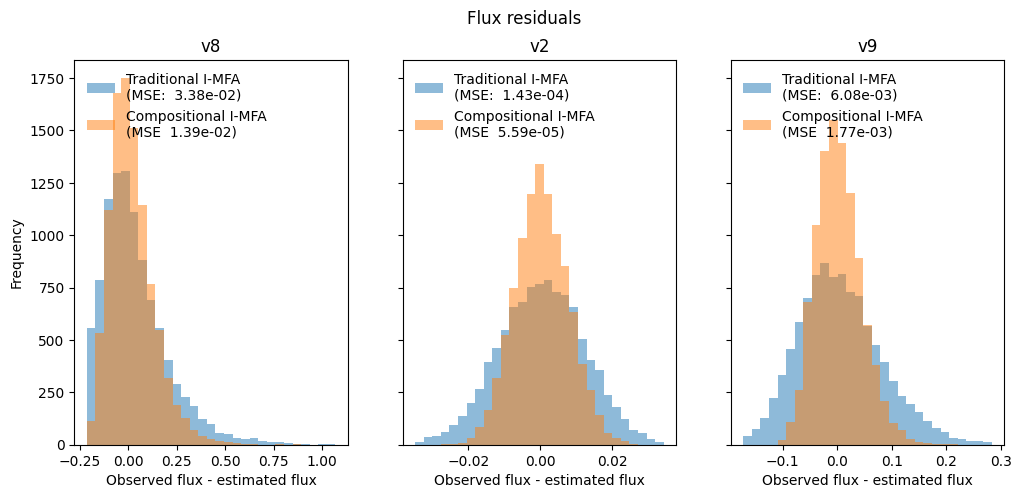

In [11]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, i].flatten()
    resid_comp_i = resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_tca.png", bbox_inches="tight", dpi=200)

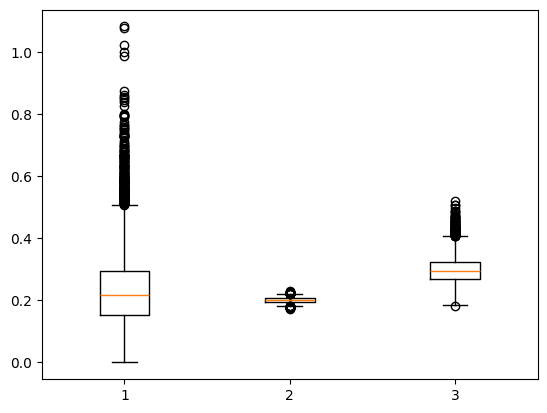

In [12]:
plt.boxplot(estimated_fluxes_ref["ilr"][:,:])
plt.show()

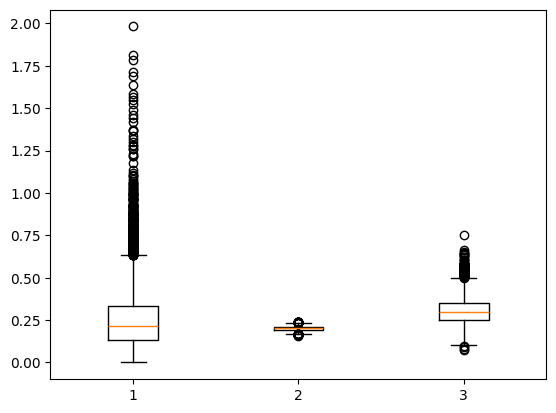

In [13]:
plt.boxplot(estimated_fluxes_ref["trad"][:,:])
plt.show()

In [14]:
resid_diff = resid_trad[:, :]**2 - resid_ilr[:, :]**2
mse_diff = (resid_diff).mean(axis=(0))
print(mse_diff)

[1.99611192e-02 8.67787309e-05 4.31697438e-03]


In [15]:
np.median(resid_diff, axis=0)

array([2.78067680e-03, 3.13088996e-05, 1.41279507e-03])

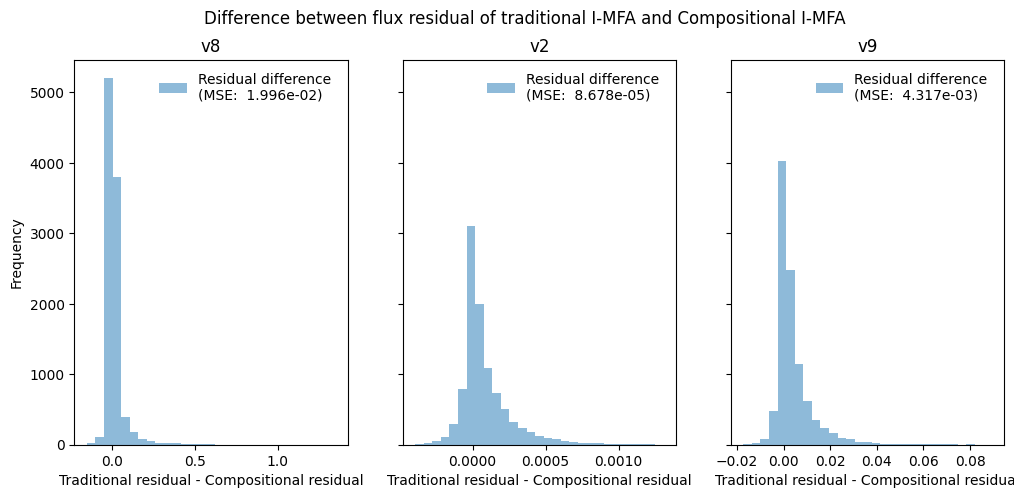

In [16]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_diff[:,i].flatten()
    xmin = np.quantile(resid_trad_i, 0.001)
    xmax = np.quantile(resid_trad_i, 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Residual difference \n(MSE: {mse_diff[i]: .3e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Traditional residual - Compositional residual")
    ax.legend(frameon=False, loc="upper right")
axes[0].set_ylabel("Frequency");

f.suptitle("Difference between flux residual of traditional I-MFA and Compositional I-MFA");
f.savefig(PLOT_DIR / "flux_residuals_tca.png", bbox_inches="tight", dpi=200)

In [17]:
flux_ci_trad_ref = jnp.exp(jnp.log(flux_ci_ref["trad"][:,:,:]).mean(axis=0))
flux_ci_ilr_ref = jnp.exp(jnp.log(flux_ci_ref["ilr"][:,:,:]).mean(axis=0))

In [18]:
flux_ci_trad_ref = flux_ci_ref["trad"][364,:,:]
flux_ci_ilr_ref = flux_ci_ref["ilr"][364,:,:]

In [19]:
max(flux_ci_ref["ilr"][:,0,0])

Array(0.12752089, dtype=float64)

In [20]:
flux = list(true_flux.keys())
print(f"{'Traditional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_trad_ref):
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

               Traditional                
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v8     |          0.0000 |      22070.8915
v1     |          1.0000 |          1.0000
v19    |          0.0500 |          0.0500
v20    |          0.0300 |          0.0300
v16    |          0.0700 |          0.0700
v17    |          0.2300 |          0.2300
v18    |          0.1200 |          0.1200
v2     |          0.1183 |          0.4037
v9     |          0.0544 |          8.1624
v3     |          0.3457 |          1.1795
v4     |          0.3457 |          1.1795
v5     |          0.3457 |          1.1795
v6     |          0.1838 |          2.1395
v11    |          0.2008 |          7.9760
v12    |          0.1698 |          0.5792
v13    |          0.1357 |         18.3824
v14    |          0.0848 |         39.1906
v15    |          0.0006 |      51035.8972
v10    |          0.0926 |          7.3954
v7     |          0.0000 |     501951.9113


In [21]:
print(f"{'Compositional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_ilr_ref):
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

              Compositional               
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v8     |          0.0169 |          1.5669
v1     |          1.0000 |          1.0000
v19    |          0.0500 |          0.0500
v20    |          0.0300 |          0.0300
v16    |          0.0700 |          0.0700
v17    |          0.2300 |          0.2300
v18    |          0.1200 |          0.1200
v2     |          0.1776 |          0.2474
v9     |          0.2303 |          0.8748
v3     |          0.5334 |          0.7432
v4     |          0.5334 |          0.7432
v5     |          0.5334 |          0.7432
v6     |          0.4373 |          0.8489
v11    |          0.7533 |          2.0376
v12    |          0.2581 |          0.3596
v13    |          0.7951 |          2.9965
v14    |          0.7760 |          4.0747
v15    |          0.3850 |         80.1460
v10    |          0.3295 |          1.1638
v7     |          0.0695 |          8.5747


In [22]:
v8_trad = flux_ci_ref["trad"][:,0,:]
v2_trad = flux_ci_ref["trad"][:,7,:]
v9_trad = flux_ci_ref["trad"][:,8,:]

v8_ilr = flux_ci_ref["ilr"][:,0,:]
v2_ilr = flux_ci_ref["ilr"][:,7,:]
v9_ilr  = flux_ci_ref["ilr"][:,8,:]

In [23]:
sum((v8_ilr[:,1])>10)

Array(110, dtype=int64, weak_type=True)

In [24]:
sum((v8_trad[:,1])>10)

Array(10000, dtype=int64, weak_type=True)

In [25]:
sum((v8_ilr[:,0])<1e-2)

Array(1717, dtype=int64, weak_type=True)

In [26]:
sum((v8_trad[:,0])<1e-2)

Array(10000, dtype=int64, weak_type=True)

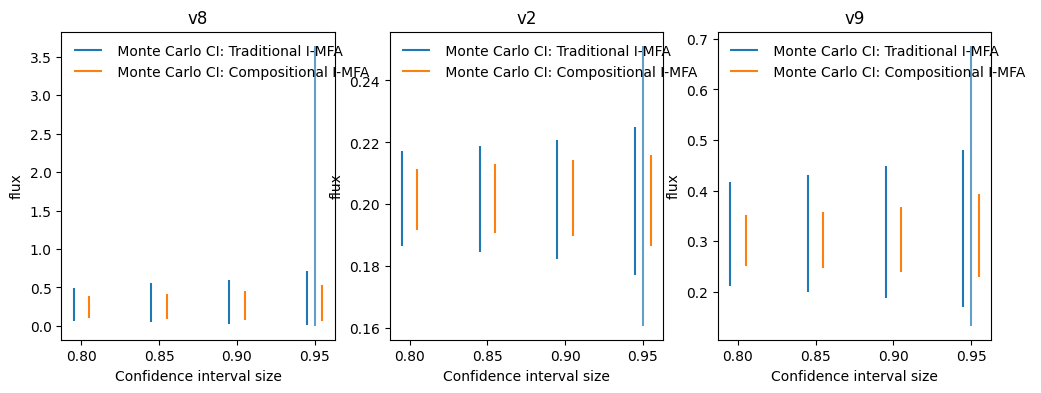

In [75]:
def get_ci_bounds(ci_size):
    low = (1.0 - ci_size) / 2
    high = 1.0 - low
    return low, high


with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    mc_estimated_fluxes = pickle.load(f)

N_BOUND = 4

plot_df_rows = []
ci_sizes = np.linspace(0.80, 0.95, N_BOUND)
for i, ci_size in enumerate(ci_sizes):
    row = {"ci_size": ci_size}
    qlow, qhigh = get_ci_bounds(ci_size)
    for model in ("trad", "ilr"):
        row[f"{model}_low_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qlow, axis=0)
        row[f"{model}_low_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qlow, axis=0)
        row[f"{model}_low_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qlow, axis=0)
        row[f"{model}_high_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qhigh, axis=0)
        row[f"{model}_high_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qhigh, axis=0)
        row[f"{model}_high_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qhigh, axis=0)
    plot_df_rows.append(row)

plot_df = pl.DataFrame(plot_df_rows)
f, axes = plt.subplots(1, 3, figsize=[12, 4])
axes = axes.ravel()
for ax, flux_ix in zip(axes, (0, 1, 2)):
    for offset, model, color in zip((-0.005, 0.005), ("trad", "ilr"), ("tab:blue", "tab:orange")):
        ax.vlines(
            plot_df["ci_size"] + offset, 
            plot_df[f"{model}_low_{flux_ix}"], 
            plot_df[f"{model}_high_{flux_ix}"], 
            color=color,
            label=" Monte Carlo CI: " + model.replace("ilr", "Compositional I-MFA").replace("trad", "Traditional I-MFA")
        )
    # ax.axhline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]: .2f})")
    ax.set(xlabel="Confidence interval size", ylabel="flux", title=f"v{free_flux_numbers[flux_ix]}")
    ax.legend(frameon=False, loc="upper left")
x_pos = np.full((1000, 1), 0.95)
axes[0].vlines(x=0.95,  ymin=np.quantile(v8_ilr[:,0],0.05), ymax = np.quantile(v8_ilr[:,1],0.95), alpha=0.7)
axes[1].vlines(x=0.95,  ymin=np.quantile(v2_ilr[:,0],0.05), ymax = np.quantile(v2_ilr[:,1],0.95), alpha=0.7)
axes[2].vlines(x=0.95,  ymin=np.quantile(v9_ilr[:,0],0.05), ymax = np.quantile(v9_ilr[:,1],0.95), alpha=0.7)
# axes[1].vlines(x=x_pos,  ymin=v2_ilr[:,0], ymax = v2_ilr[:,1], alpha=0.1)
# axes[2].vlines(x=x_pos,  ymin=v9_ilr[:,0], ymax = v9_ilr[:,1], alpha=0.1)

plt.show()

# Sensitivity

In [16]:
free_fluxes = jnp.load(RESULTS_DIR / "free_fluxes.npy", allow_pickle=True)
free_fluxes.shape

(125, 3)

In [17]:
target = np.array([[true_flux['v8'], true_flux['v2'], true_flux['v9']]])
true_flux_index= np.where(np.isclose(free_fluxes,target).all(axis=1))[0].item()
free_fluxes[true_flux_index]

Array([0.215, 0.201, 0.296], dtype=float64)

In [18]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements.npy", allow_pickle=True)
type(intensity_msts)

list

In [19]:
true_ids = jnp.load(RESULTS_DIR / "true_isotopologue_distributions.npy", allow_pickle=True)
type(true_ids)

list

In [20]:
with open(RESULTS_DIR / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes = pickle.load(f)

In [21]:
with open(RESULTS_DIR / "estimated_ids.pkl", "rb") as f:
    estimated_ids = pickle.load(f)

In [22]:
estimated_fluxes["trad"].shape

(125, 50, 3)

In [23]:
resid_trad = (free_fluxes[:, None, :] - estimated_fluxes["trad"][:, :, :])/free_fluxes[:, None, :]
resid_clr = (free_fluxes[:, None, :] - estimated_fluxes["clr"][:, :, :])/free_fluxes[:, None, :]
resid_ilr = (free_fluxes[:, None, :] - estimated_fluxes["ilr"][:, :, :])/free_fluxes[:, None, :]

mse_trad = (resid_trad ** 2).mean(axis=(0, 1))
mse_clr = (resid_clr ** 2).mean(axis=(0, 1))
mse_ilr = (resid_ilr ** 2).mean(axis=(0, 1))

mse_trad, mse_clr, mse_ilr

(Array([1.82881475, 0.0046557 , 0.08802448], dtype=float64),
 Array([0.35728181, 0.00159864, 0.02033965], dtype=float64),
 Array([0.35621251, 0.00160606, 0.02040895], dtype=float64))

In [24]:
id_resid_trad = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["trad"])
]
id_resid_clr = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["clr"])
]
id_resid_ilr = [
    [
        {k: true_ids[i][k] - est_val[k] for k in true_ids[0]}
        for est_val in trad_row
    ]
    for i, trad_row in enumerate(estimated_ids["ilr"])
]

n_elements = len(id_resid_trad) * len(id_resid_trad[0])

id_mse_trad = {
    k: sum(row[col][k]**2 for row in id_resid_trad for col in range(len(row))) / n_elements
    for k in true_ids[0]
}
id_mse_clr = {
    k: sum(row[col][k]**2 for row in id_resid_clr for col in range(len(row))) / n_elements
    for k in true_ids[0]
}
id_mse_ilr = {
    k: sum(row[col][k]**2 for row in id_resid_ilr for col in range(len(row))) / n_elements
    for k in true_ids[0]
}


IndexError: Too many indices: array is 2-dimensional, but 3 were indexed

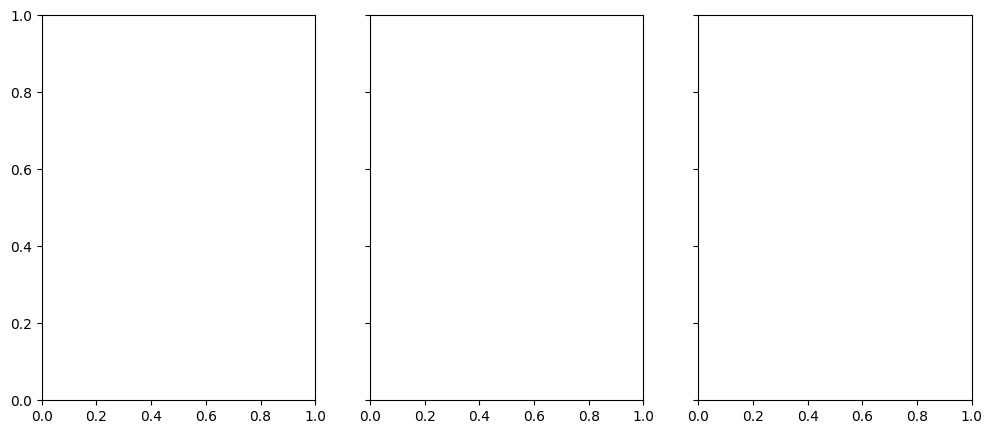

In [ ]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()
    resid_comp_i = resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
# f.savefig(PLOT_DIR / "flux_residuals_toy.png", bbox_inches="tight", dpi=200)

IndexError: Too many indices: array is 2-dimensional, but 3 were indexed

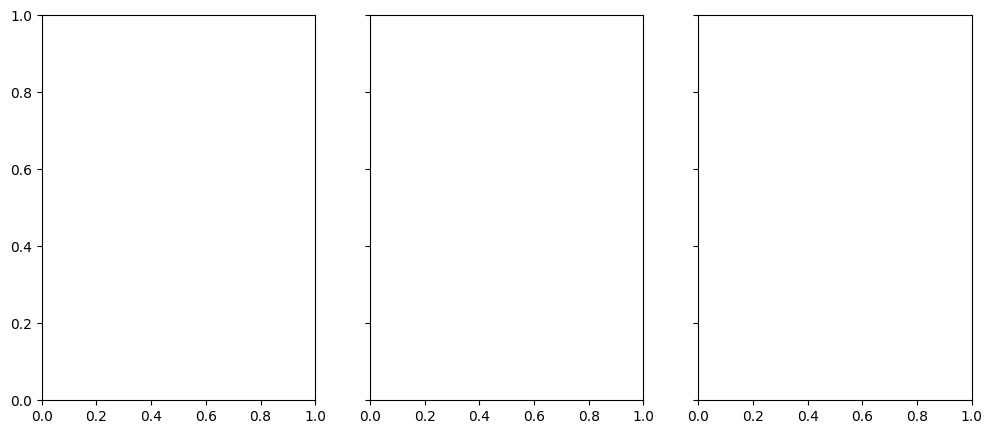

In [ ]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()-resid_ilr[:, :, i].flatten()
    # xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    # xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    # bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=30,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=30,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");

In [26]:
id_resid_trad_lysx = jnp.array([
    id_resid_trad[i][j]["lysx_123456"] 
    for i in range(len(free_fluxes)) 
    for j in range(50)
])

id_resid_ilr_lysx = jnp.array([
    id_resid_ilr[i][j]["lysx_123456"] 
    for i in range(len(free_fluxes)) 
    for j in range(50)
])

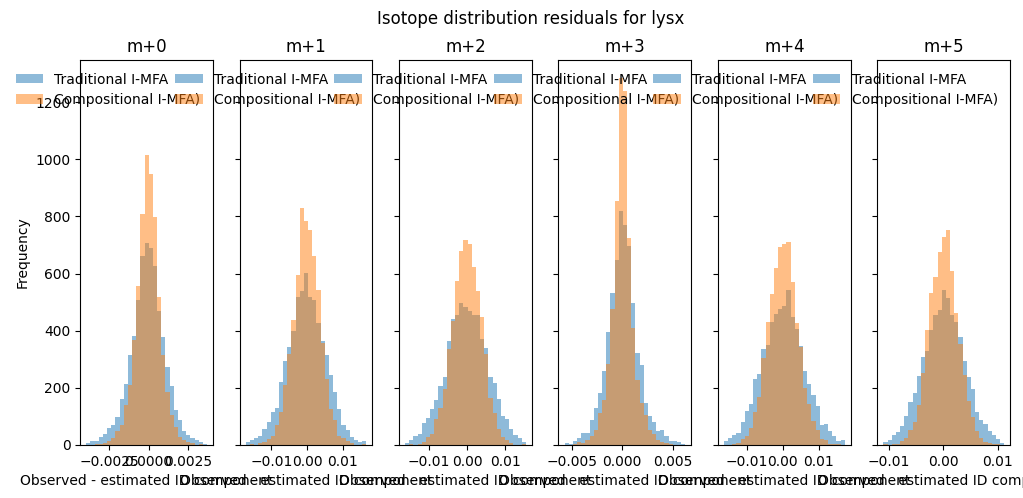

In [27]:
f, axes = plt.subplots(1, 6, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad_lysx[:, i].flatten()
    resid_comp_i = id_resid_ilr_lysx[:, i].flatten()
    xmin = np.quantile(resid_trad_i, 0.001)
    xmax = np.quantile(resid_trad_i, 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA)" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"m+{i}", xlabel="Observed - estimated ID component")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Isotope distribution residuals for lysx");

In [28]:
with open(RESULTS_DIR / "entropies.npy", "rb") as f:
    entropies = pickle.load(f)
len(entropies)

125

In [29]:
entropies_max = [max(idx.values()) for idx in entropies]
diff_flux = ((resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1))
# /(resid_trad ** 2).mean(axis=1)

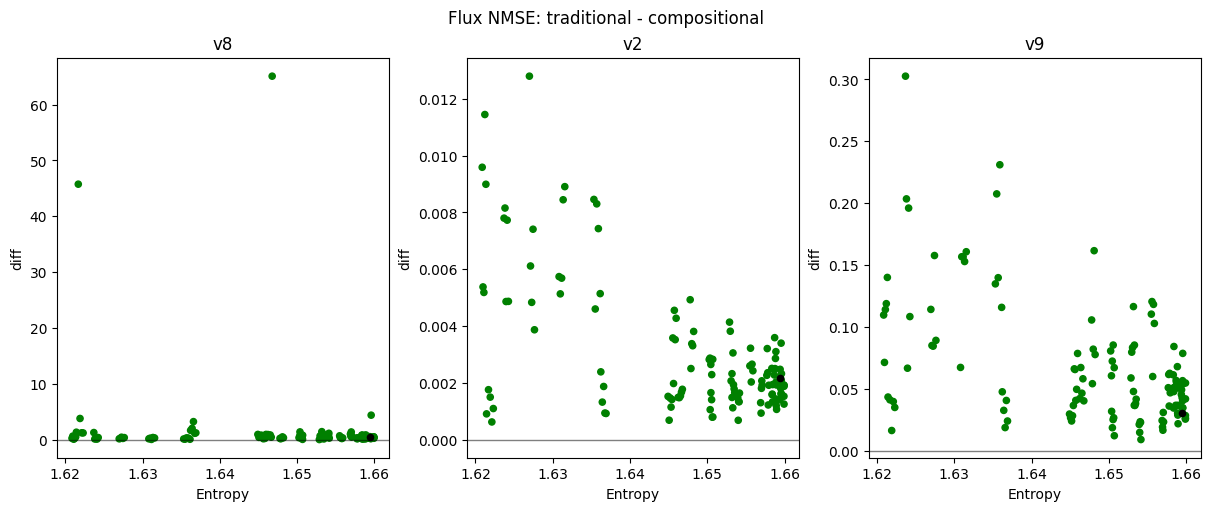

In [30]:
f, axes = plt.subplots(1, 3, figsize=[12, 5], layout= "constrained")
axes = axes.ravel()
point_size=20
for i in range(3):
    y_values = diff_flux[:,i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies_max, y_values, c=colors, s=point_size)
    axes[i].scatter(entropies_max[true_flux_index], y_values[true_flux_index], color="black", s=point_size)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5, label="Reference flux")
    axes[i].set(xlabel="Entropy", ylabel="diff", title=f"v{free_flux_numbers[i]}")
f.suptitle("Flux NMSE: traditional - compositional")

plt.show()

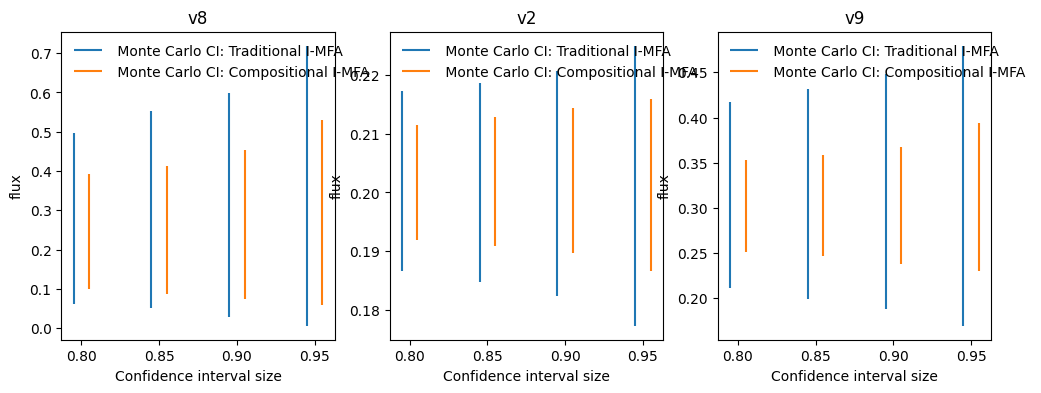

In [31]:
def get_ci_bounds(ci_size):
    low = (1.0 - ci_size) / 2
    high = 1.0 - low
    return low, high


with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    mc_estimated_fluxes = pickle.load(f)

N_BOUND = 4

plot_df_rows = []
ci_sizes = np.linspace(0.80, 0.95, N_BOUND)
for i, ci_size in enumerate(ci_sizes):
    row = {"ci_size": ci_size}
    qlow, qhigh = get_ci_bounds(ci_size)
    for model in ("trad", "ilr"):
        row[f"{model}_low_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qlow, axis=0)
        row[f"{model}_low_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qlow, axis=0)
        row[f"{model}_low_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qlow, axis=0)
        row[f"{model}_high_0"] = np.quantile(mc_estimated_fluxes[model][:, 0], qhigh, axis=0)
        row[f"{model}_high_1"] = np.quantile(mc_estimated_fluxes[model][:, 1], qhigh, axis=0)
        row[f"{model}_high_2"] = np.quantile(mc_estimated_fluxes[model][:, 2], qhigh, axis=0)
    plot_df_rows.append(row)


plot_df = pl.DataFrame(plot_df_rows)
f, axes = plt.subplots(1, 3, figsize=[12, 4])
axes = axes.ravel()
for ax, flux_ix in zip(axes, (0, 1, 2)):
    for offset, model, color in zip((-0.005, 0.005), ("trad", "ilr"), ("tab:blue", "tab:orange")):
        ax.vlines(
            plot_df["ci_size"] + offset, 
            plot_df[f"{model}_low_{flux_ix}"], 
            plot_df[f"{model}_high_{flux_ix}"], 
            color=color,
            label=" Monte Carlo CI: " + model.replace("ilr", "Compositional I-MFA").replace("trad", "Traditional I-MFA")
        )
    # ax.axhline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]: .2f})")
    ax.set(xlabel="Confidence interval size", ylabel="flux", title=f"v{free_flux_numbers[flux_ix]}")
    ax.legend(frameon=False, loc="upper left")